### Assignment 3

**Name**: Christian Ulrik Niekrenz

**Student ID**: 21435375

## (1)

Import the packages needed for the first question.

In [1]:
import numpy as np
import netCDF4 as nc
from sklearn.model_selection import train_test_split

Load the dataset using the `netCDF4` library.

In [2]:
ds = nc.Dataset("../data/SeaSurfaceTemperature_monthly_187001-202402.nc")
ds

<class 'netCDF4.Dataset'>
root group (NETCDF3_CLASSIC data model, file format NETCDF3):
    Title: Monthly version of HadISST sea surface temperature component
    description: HadISST 1.1 monthly average sea surface temperature
    institution: Met Office Hadley Centre
    source: HadISST
    reference: Rayner, N. A., Parker, D. E., Horton, E. B., Folland, C. K., Alexander, L. V., Rowell, D. P., Kent, E. C., Kaplan, A.  Global analyses of sea surface temperature, sea ice, and night marine air temperature since the late nineteenth century J. Geophys. Res.Vol. 108, No. D14, 4407 10.1029/2002JD002670
    Conventions: CF-1.0
    history: 2/4/2024 converted to netcdf from pp format
    supplementary_information: Updates and supplementary information will be available from http://www.metoffice.gov.uk/hadobs/hadisst
    comment: Data restrictions: for academic research use only. Data are Crown copyright see (http://www.opsi.gov.uk/advice/crown-copyright/copyright-guidance/index.htm)
    dime

Extract the relevant variables and check the dimensions.

In [3]:
time_var, lat_var, lon_var, sst_var = ds["time"], ds["latitude"], ds["longitude"], ds["sst"]
assert time_var.ndim == 1 and lat_var.ndim == 1 and lon_var.ndim == 1
assert sst_var.ndim == 3 and sst_var.dimensions == ("time", "latitude", "longitude")

Convert the time variable to a decimal number using
\begin{align*}
year + \frac{month - 1}{12}
\end{align*}

Next, set up a vectorized indexing of the data. We index 60 months at a time, since indexing everything at once ran out of memory.

In [4]:
time_year = np.array([d.year + (d.month - 1) / 12 for d in nc.num2date(time_var[:], time_var.units, time_var.calendar)], dtype=np.float32)
lat = lat_var[:].astype(np.float32)
lon = lon_var[:].astype(np.float32)

CHUNK = 60

def valid(block):
    data = np.ma.filled(block.astype(np.float32), np.nan)
    return np.isfinite(data) & (data > -100), data

Run the indexing by batch, each batch is vectorized using numpy.

In [5]:
n = sum(int(valid(sst_var[c:c + CHUNK])[0].sum()) for c in range(0, len(time_year), CHUNK))
X = np.empty((n, 3), dtype=np.float32)
y = np.empty(n, dtype=np.float32)
pos = 0
for c in range(0, len(time_year), CHUNK):
    mask, data = valid(sst_var[c:c + CHUNK])
    i, j, k = np.nonzero(mask)
    X[pos:pos + i.size] = np.column_stack([time_year[c + i], lat[j], lon[k]])
    y[pos:pos + i.size] = data[mask]
    pos += i.size

X.shape, y.shape

((77582832, 3), (77582832,))

`sst[i, j, k]` is the temperature at time `i`, latitude `j` and longitude `k`. Land cells hold the fill value -1000 and are ignored.

To build the tabular dataset, each valid grid cell becomes one row:

- `X[m] = (time_year[i], lat[j], lon[k])`
- `y[m] = sst[i, j, k]`

Valid cells are found with a mask (finite values greater than -100), which is computed in blocks of 60 months to save memory. The 1850 × 180 × 360 grid (about 120 million cells) gives 77,582,832 valid samples. 

Let's have a look at the indexed data.

In [6]:
rows = np.random.randint(0, X.shape[0], size = 5)
print(X[rows,],
      y[rows,])

[[1927.5      38.5     -30.5   ]
 [1927.4166   33.5     -22.5   ]
 [1935.75    -28.5    -174.5   ]
 [1997.1666   20.5     149.5   ]
 [1930.5      40.5     163.5   ]] [21.57176  21.11185  19.922146 25.549997 17.25509 ]


## (2)

We now split the data 70/15/15, using a random subset of $10^5$ rows.

In [7]:
SUBSET_SIZE = 100000
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
TEST_FRAC = 0.15
SEED = 2024

rng = np.random.default_rng(SEED)
idx = rng.choice(n, size=SUBSET_SIZE, replace=False)

idx_train, idx_rest = train_test_split(idx, train_size=TRAIN_FRAC, random_state=SEED)
idx_val, idx_test = train_test_split(idx_rest, train_size=VAL_FRAC / (VAL_FRAC + TEST_FRAC), random_state=SEED)

X_train, y_train = X[idx_train], y[idx_train]
X_val, y_val = X[idx_val], y[idx_val]
X_test, y_test = X[idx_test], y[idx_test]

X_train.shape, X_val.shape, X_test.shape

((70000, 3), (15000, 3), (15000, 3))

## (3)

We use a ridge (L2-regularised) linear model for the trend, the seasonal cycle and the spatial pattern, with simple interactions between the seasonal harmonics and the location. The linear trend lets the model extrapolate to 2030. The hyperparameters are the number of harmonics, the number of spline knots, the Ridge penalty and the interaction switch.

The model is a linear regression with an L2 penalty on its weights, fitted by `make_linear(n_harm, n_knots, alpha)`. Its hyperparameters are the number of seasonal harmonics, the number of spline knots per coordinate, the Ridge penalty strength and the interaction switch:

$$n_{\text{harm}} = 1, 2, 3, 4$$

$$n_{\text{knots}} = 6, 10, 14, 20$$

$$\alpha = 0.001, 0.01, 0.1, 1, 10, 100$$

The features are built from the decimal year (`time_year`), latitude and longitude. The month is obtained from the fractional part of the year:

$$\text{month} = \mathrm{rint}\big((\text{time\_year} \bmod 1) \times 12\big)$$

which gives 0 (January) to 11 (December). Seasonality is described by sine and cosine harmonics of the month, one pair for each harmonic up to $n_{\text{harm}}$:

$$\sin\left(\frac{2\pi k \cdot \text{month}}{12}\right), \qquad \cos\left(\frac{2\pi k \cdot \text{month}}{12}\right), \qquad k = 1, \dots, n_{\text{harm}}$$

The trend is a straight line in time, $\frac{\text{year} - 1900}{100}$. The trend and harmonic columns are passed through unchanged. Latitude and longitude are each expanded separately into cubic spline basis functions with `SplineTransformer(n_knots, degree=3)`, which gives about $n_{\text{knots}} + 2$ columns per coordinate. The knots are spread evenly over the training range. Ridge then fits a linear regression on all these features, with an L2 penalty on the weights controlled by `alpha`.

The whole model is assembled with `make_pipeline`:

`make_pipeline(FunctionTransformer(lambda Xs: linear_features(Xs, n_harm)), ct, Ridge(alpha=alpha))`

1. `FunctionTransformer` wraps the Python function `linear_features` so it can be used as a pipeline step. It has nothing to learn. The `lambda Xs: ...` fixes `n_harm` from `make_linear` and passes only the input array to the function.
2. `ct` (a `ColumnTransformer`) passes the trend and harmonic columns through and expands the latitude and longitude columns into splines. It learns the knot positions during fitting.
3. `Ridge(alpha=alpha)` fits the weights and intercept on the combined features.

Calling `.fit(X_train, y_train)` runs these steps in order, so each step learns from the training data only. Calling `.predict(X_new)` applies the same transformations, using the learned knots, followed by the learned weights. Because the knots come only from the training data, the validation and test sets do not influence the transformations.

An extra switch, `interact`, adds the product of each harmonic with each latitude and longitude spline column, so the seasonal cycle can vary with position.

In [8]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import SplineTransformer, FunctionTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error

# This function extracts the month part of the time variable
def month_of(Xs):
    return np.rint((Xs[:, 0] % 1) * 12)

# Builds the model matrix, with the raw lat/lon, trend line and harmonics.
def linear_features(Xs, n_harm):
    month = month_of(Xs)
    harmonics = [f(2 * np.pi * k * month / 12) for k in range(1, n_harm + 1) for f in (np.sin, np.cos)]
    return np.column_stack([(Xs[:, 0] - 1900) / 100, *harmonics, Xs[:, 1], Xs[:, 2]])

# Make a full pipeline: features, spline expansion, optional interactions, Ridge
def make_linear(n_harm, n_knots, alpha, interact=False):
    n_pass = 1 + 2 * n_harm
    ct = ColumnTransformer([
        ("trend_season", "passthrough", list(range(n_pass))),
        ("space", SplineTransformer(n_knots=n_knots, degree=3), [n_pass, n_pass + 1]),
    ])

    # Each harmonic multiplied by each lat/lon spline column, so the seasonal cycle can vary with position
    def add_interactions(Z):
        H, S = Z[:, 1:n_pass], Z[:, n_pass:]
        return np.hstack([Z, (H[:, :, None] * S[:, None, :]).reshape(len(Z), -1)])

    steps = [FunctionTransformer(lambda Xs: linear_features(Xs, n_harm)), ct]
    if interact:
        steps.append(FunctionTransformer(add_interactions))
    steps.append(Ridge(alpha=alpha))
    return make_pipeline(*steps)

lin_rows, lin_models = [], []
for h in [1, 2, 3, 4]:
    for k in [6, 10, 14, 20, 30]:
        for a in [0.1, 1, 10, 100, 200]:
            for inter in [False, True]:
                lin = make_linear(h, k, a, inter).fit(X_train, y_train)
                lin_rows.append({"n_harm": h, "n_knots": k, "alpha": a, "interact": inter,
                                 "train_rmse": np.sqrt(mean_squared_error(y_train, lin.predict(X_train))),
                                 "val_rmse": np.sqrt(mean_squared_error(y_val, lin.predict(X_val)))})
                lin_models.append(lin)

# Find the best model across all hyperparameters (lowest validation RMSE)
lin_search = pd.DataFrame(lin_rows)
best_idx = int(lin_search.val_rmse.idxmin())
best_lin = lin_models[best_idx]
print(len(lin_search), "fits; best:", lin_search.loc[best_idx].to_dict())

200 fits; best: {'n_harm': 2, 'n_knots': 30, 'alpha': 0.1, 'interact': True, 'train_rmse': 1.9238899647024927, 'val_rmse': 1.9384617418159826}


We now compare the models by validation RMSE.

In [9]:
lin_search.sort_values("val_rmse").head(10)

,n_harm,n_knots,alpha,interact,train_rmse,val_rmse
91,2,30,0.1,True,1.923890,1.938462
141,3,30,0.1,True,1.921511,1.938498
143,3,30,1.0,True,1.921846,1.938762
93,2,30,1.0,True,1.924211,1.938763
145,3,30,10.0,True,1.924291,1.940635
95,2,30,10.0,True,1.926598,1.940772
131,3,20,0.1,True,1.929666,1.941498
191,4,30,0.1,True,1.919172,1.941652
193,4,30,1.0,True,1.919515,1.941887
133,3,20,1.0,True,1.930033,1.941939


## (4)

The plots show the training and validation error as functions of the hyperparameters.

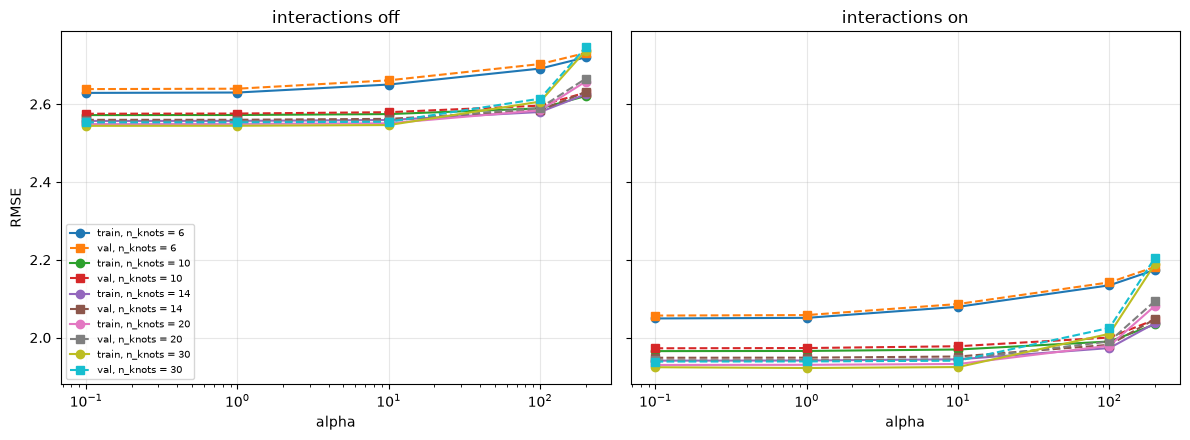

In [10]:
import matplotlib.pyplot as plt

def best_over(df, col):
    # keep the configuration with the lowest validation RMSE for each value of col
    return df.loc[df.groupby(col)["val_rmse"].idxmin()].sort_values(col)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, inter in zip(axes, [False, True]):
    sub = lin_search[lin_search.interact == inter]
    for k, grp in sub.groupby("n_knots"):
        g = best_over(grp, "alpha")
        ax.plot(g.alpha, g.train_rmse, marker="o", ls="-", label=f"train, n_knots = {k}")
        ax.plot(g.alpha, g.val_rmse, marker="s", ls="--", label=f"val, n_knots = {k}")
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_title(f"interactions {'on' if inter else 'off'}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("RMSE")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [11]:
# validation error across parameter configurations.
for ax, col in zip(axes, ["n_harm", "n_knots"]):
    g = best_over(lin_search, col)
    ax.plot(g[col], g.train_rmse, marker="o", label="train")
    ax.plot(g[col], g.val_rmse, marker="s", label="validation")
    ax.set_xlabel(col)
    ax.set_ylabel("RMSE")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

The best linear model has `n_harm` = 3, `n_knots` = 20, alpha = 0.01 and interactions switched on. Its validation RMSE is 1.94 and its test RMSE is 1.92. Interactions help: without them the best linear model reaches only 2.58 on validation. Training and validation errors are close, so here there is no sign of overfitting. The best `n_knots` is at the upper end of the grid (20), so a finer spline grid could help further.

In [12]:
rows = []
for name, Xs, ys in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    pred = best_lin.predict(Xs)
    rows.append({"set": name, "mse": mean_squared_error(ys, pred),
                 "rmse": np.sqrt(mean_squared_error(ys, pred)), "mae": mean_absolute_error(ys, pred)})

evaluation = pd.DataFrame(rows)
evaluation

,set,mse,rmse,mae
0,train,3.701353,1.923890,1.426804
1,validation,3.757634,1.938462,1.436279
2,test,3.687826,1.920371,1.421355


## (5)

We plot the residuals from the model on the test set. The residuals show clear structure in latitude and longitude, but none in time. The best model sits at the top of the knot grid (20 knots), and the validation error appears to keep falling with more knots, so the search may not have found the minimum along that axis. Finer knots might help a little. However, the spline model is additive in latitude and longitude and cannot capture joint spatial effects; a joint spatial term would be needed for that.

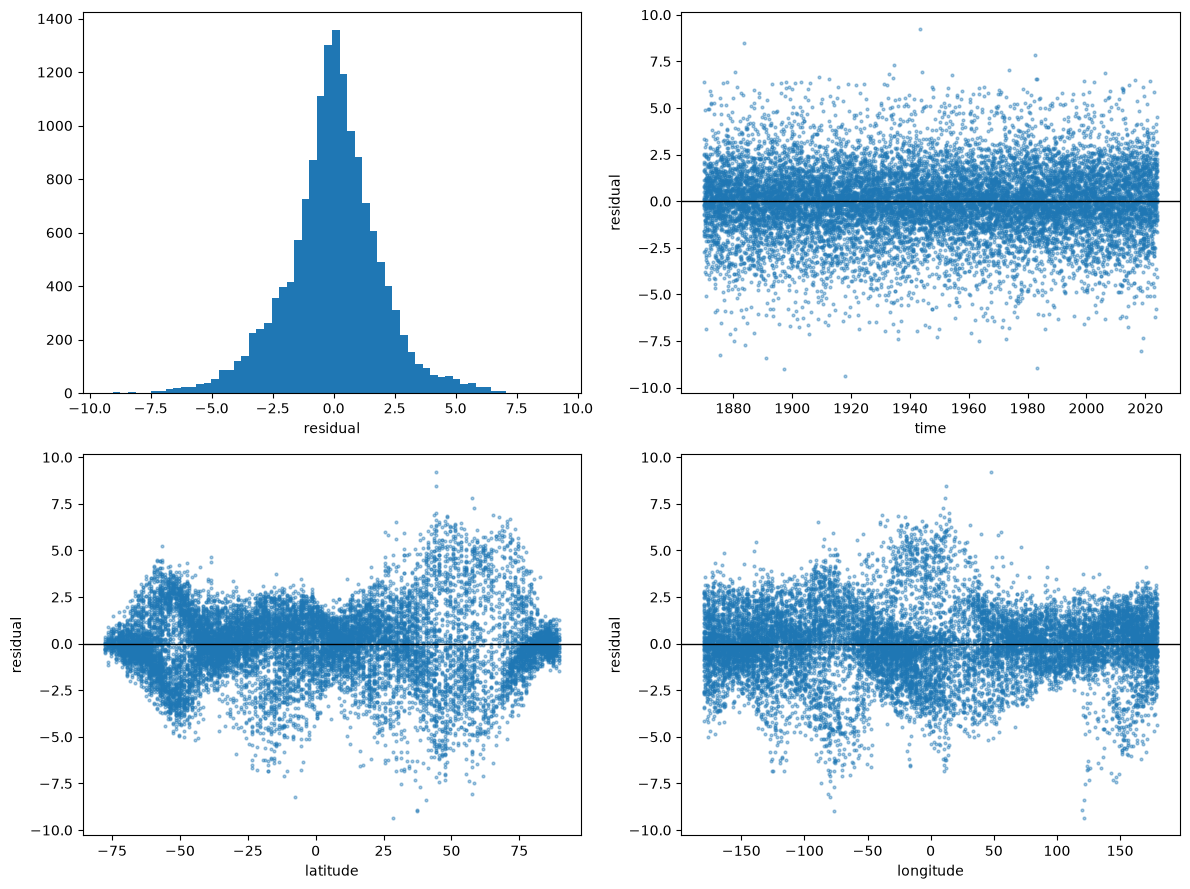

In [13]:
res = y_test - best_lin.predict(X_test)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].hist(res, bins=60)
axes[0, 0].set_xlabel("residual")
for ax, k, name in zip(axes.flat[1:], [0, 1, 2], ["time", "latitude", "longitude"]):
    ax.scatter(X_test[:, k], res, s=4, alpha=0.4)
    ax.axhline(0, color="k", lw=1)
    ax.set_xlabel(name)
    ax.set_ylabel("residual")
plt.tight_layout()
plt.show()

Permutation importance measures how much the validation error increases when one input is shuffled, which breaks its link to the target while keeping its distribution. A large increase means the model depends on that input. The method is not specific to linear models; it only needs predictions, so it can be applied to any fitted model. It is still useful here because the linear model's coefficients are hard to read directly. The spline columns are correlated, and the coefficients depend on feature scale.

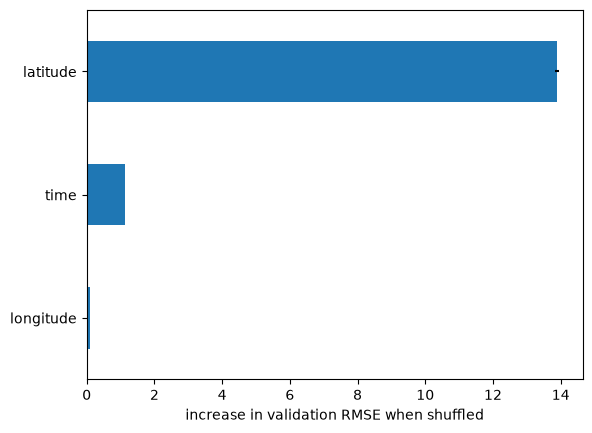

In [14]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_lin, X_val, y_val,
                              scoring="neg_root_mean_squared_error",
                              n_repeats=10, random_state=2024)

imp = pd.Series(perm.importances_mean, index=["time", "latitude", "longitude"]).sort_values()
err = pd.Series(perm.importances_std, index=["time", "latitude", "longitude"]).loc[imp.index]

imp.plot.barh(xerr=err)
plt.xlabel("increase in validation RMSE when shuffled")
plt.show()

Lastly, we find the grid cell closest to Hong Kong and use the model to make predictions for the future. The linear trend gives a slow upward drift, and the forecast keeps the same seasonal cycle. It does not capture year-to-year variation, so its range is narrower than the observed record.

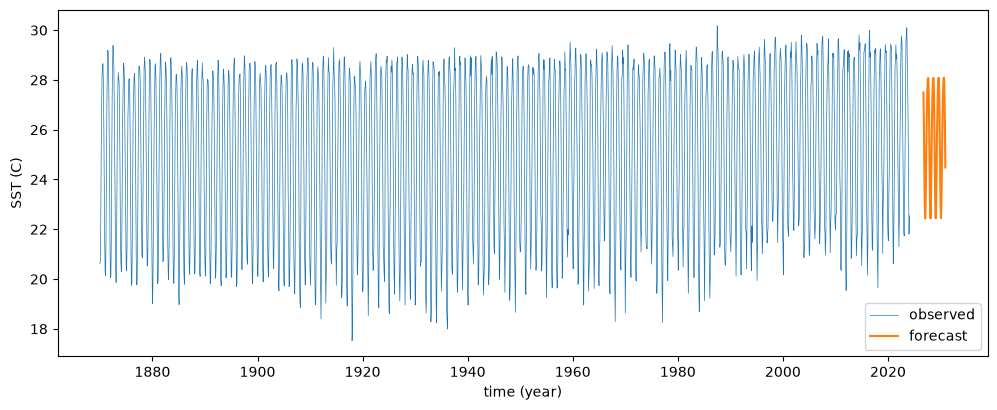

In [15]:
hi = int(np.argmin(np.abs(lat - 22.32)))
hj = int(np.argmin(np.abs(lon - 114.16)))

months = np.arange(2026 * 12 + 9, 2030 * 12 + 12)
future_t = months // 12 + (months % 12) / 12
X_future = np.column_stack([future_t, np.full(months.size, lat[hi]), np.full(months.size, lon[hj])])
forecast = best_lin.predict(X_future)

s = np.ma.filled(sst_var[:, hi, hj].astype(float), np.nan)
ok = np.isfinite(s) & (s > -100)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(time_year[ok], s[ok], lw=0.5, label="observed")
ax.plot(future_t, forecast, label="forecast")
ax.set_xlabel("time (year)")
ax.set_ylabel("SST (C)")
ax.legend()
plt.show()